In [17]:
# Suppress deprecation warnings to keep output clean and readable in Jupyter/Colab

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [18]:
# Import required libraries for data manipulation, visualization, and Market Basket Analysis (Apriori)
# mlxtend is used for frequent itemset mining and association rule generation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

In [19]:
# Load the groceries dataset from CSV file and read each transaction as a separate line
# Each row represents a single transaction in comma-separated format

with open('groceries.csv', 'r') as file:
    groceries = file.read().splitlines()

groceries[:5]

['citrus fruit,semi-finished bread,margarine,ready soups',
 'tropical fruit,yogurt,coffee',
 'whole milk',
 'pip fruit,yogurt,cream cheese,meat spreads',
 'other vegetables,whole milk,condensed milk,long life bakery product']

In [20]:
# Split each transaction into a list of individual items using comma separation
# This converts raw text transactions into structured list format for analysis

transactions = [item.split(',') for item in groceries]

transactions[:5]

[['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups'],
 ['tropical fruit', 'yogurt', 'coffee'],
 ['whole milk'],
 ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads'],
 ['other vegetables',
  'whole milk',
  'condensed milk',
  'long life bakery product']]

In [21]:
# Convert transaction list into one-hot encoded matrix using TransactionEncoder
# Each column represents an item, and each row represents a transaction (True/False format)
# This creates the basket format required for Apriori algorithm

te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

basket = pd.DataFrame(te_array, columns=te.columns_)

basket.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [22]:
# Check the dimensions of the basket matrix (transactions × unique items)

basket.shape

(9835, 169)

In [23]:
# Check for missing values in the basket dataset to ensure data quality

basket.isnull().sum().sum()

np.int64(0)

In [24]:
# Check for duplicate transactions in the basket dataset

basket.duplicated().sum()

np.int64(2824)

In [25]:
# Apply the Apriori algorithm to generate frequent itemsets from the basket dataset
# Minimum support threshold is set to 0.01 to capture meaningful item combinations
# use_colnames=True ensures item names are shown instead of column indices

frequent_items = apriori(
    basket,
    min_support=0.01,
    use_colnames=True
)

frequent_items.head()


,support,itemsets
0,0.033452,(UHT-milk)
1,0.017692,(baking powder)
2,0.052466,(beef)
3,0.033249,(berries)
4,0.026029,(beverages)


In [26]:
# Sort frequent itemsets by support in descending order to identify the most commonly purchased items

frequent_items = frequent_items.sort_values(by='support', ascending=False)

frequent_items.head(10)

,support,itemsets
86,0.255516,(whole milk)
55,0.193493,(other vegetables)
66,0.183935,(rolls/buns)
75,0.174377,(soda)
87,0.139502,(yogurt)
6,0.110524,(bottled water)
67,0.108998,(root vegetables)
81,0.104931,(tropical fruit)
73,0.098526,(shopping bags)
70,0.093950,(sausage)


In [27]:
# Generate association rules from frequent itemsets using confidence metric
# Minimum confidence threshold is set to 0.3 to filter meaningful relationships

rules = association_rules(
    frequent_items,
    metric="confidence",
    min_threshold=0.3
)

rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(other vegetables),(whole milk),0.193493,0.255516,0.074835,0.386758,1.513634,1.0,0.025394,1.214013,0.420750,0.200000,0.176286,0.339817
1,(rolls/buns),(whole milk),0.183935,0.255516,0.056634,0.307905,1.205032,1.0,0.009636,1.075696,0.208496,0.147942,0.070369,0.264776
2,(yogurt),(whole milk),0.139502,0.255516,0.056024,0.401603,1.571735,1.0,0.020379,1.244132,0.422732,0.165267,0.196226,0.310432
3,(root vegetables),(whole milk),0.108998,0.255516,0.048907,0.448694,1.756031,1.0,0.021056,1.350401,0.483202,0.154961,0.259479,0.320049
4,(root vegetables),(other vegetables),0.108998,0.193493,0.047382,0.434701,2.246605,1.0,0.026291,1.426693,0.622764,0.185731,0.299078,0.339789


In [28]:
# Filter strong association rules based on lift and confidence thresholds
# Keep only rules with lift > 1 (positive association) and confidence > 0.3
# Sort results to highlight the strongest relationships first

strong_rules = rules[
    (rules['lift'] > 1) &
    (rules['confidence'] > 0.3)
]

strong_rules = strong_rules.sort_values(by='lift', ascending=False)

strong_rules.head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
111,"(other vegetables, citrus fruit)",(root vegetables),0.028876,0.108998,0.010371,0.359155,3.295045,1.0,0.007224,1.390354,0.717225,0.081340,0.280759,0.227152
82,"(other vegetables, tropical fruit)",(root vegetables),0.035892,0.108998,0.012303,0.342776,3.144780,1.0,0.008391,1.355705,0.707403,0.092791,0.262376,0.227825
47,(beef),(root vegetables),0.052466,0.108998,0.017387,0.331395,3.040367,1.0,0.011668,1.332628,0.708251,0.120677,0.249603,0.245455
112,"(citrus fruit, root vegetables)",(other vegetables),0.017692,0.193493,0.010371,0.586207,3.029608,1.0,0.006948,1.949059,0.681990,0.051646,0.486932,0.319903
83,"(root vegetables, tropical fruit)",(other vegetables),0.021047,0.193493,0.012303,0.584541,3.020999,1.0,0.008231,1.941244,0.683367,0.060835,0.484867,0.324062
25,"(whole milk, other vegetables)",(root vegetables),0.074835,0.108998,0.023183,0.309783,2.842082,1.0,0.015026,1.290900,0.700572,0.144304,0.225347,0.261235
122,"(whole milk, curd)",(yogurt),0.026131,0.139502,0.010066,0.385214,2.761356,1.0,0.006421,1.399671,0.654974,0.064706,0.285546,0.228686
86,"(root vegetables, rolls/buns)",(other vegetables),0.024301,0.193493,0.012201,0.502092,2.594890,1.0,0.007499,1.619792,0.629935,0.059347,0.382637,0.282575
75,"(yogurt, root vegetables)",(other vegetables),0.025826,0.193493,0.012913,0.500000,2.584078,1.0,0.007916,1.613015,0.629266,0.062562,0.380043,0.283368
56,"(whole milk, tropical fruit)",(yogurt),0.042298,0.139502,0.015150,0.358173,2.567516,1.0,0.009249,1.340701,0.637483,0.090909,0.254122,0.233387


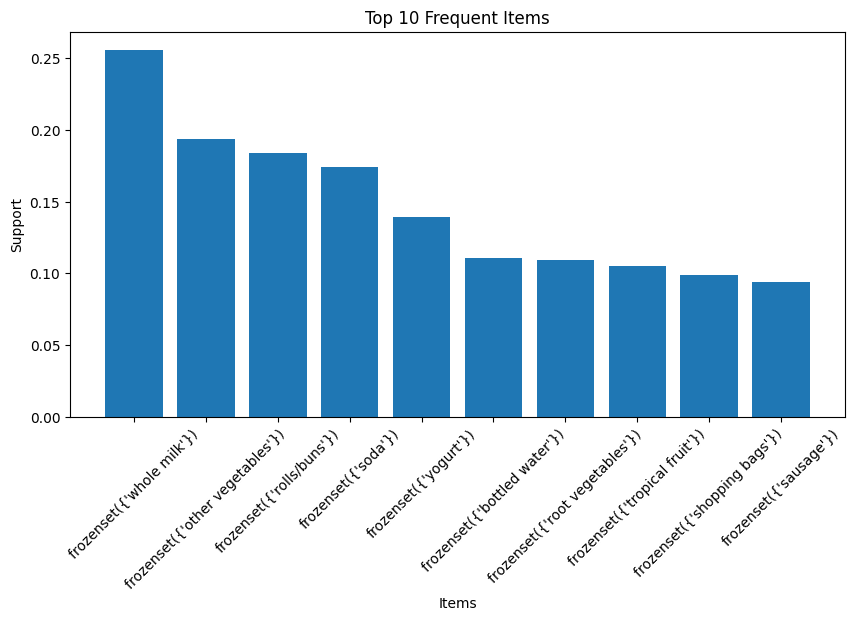

In [29]:
# Visualize the top 10 most frequent items using a bar chart based on support values

top_items = frequent_items.head(10)

plt.figure(figsize=(10,5))

plt.bar(
    top_items['itemsets'].astype(str),
    top_items['support']
)

plt.xticks(rotation=45)

plt.xlabel('Items')
plt.ylabel('Support')

plt.title('Top 10 Frequent Items')

plt.show()

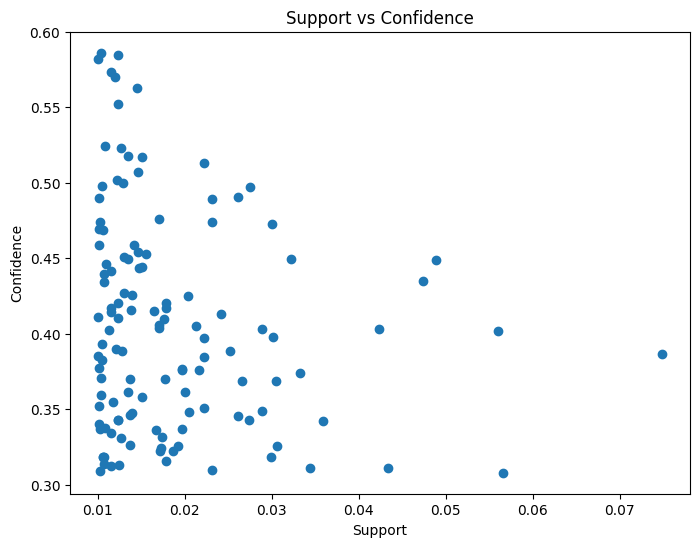

In [30]:
# Visualize relationship between support and confidence of strong association rules using a scatter plot

plt.figure(figsize=(8,6))

plt.scatter(
    strong_rules['support'],
    strong_rules['confidence']
)

plt.xlabel('Support')
plt.ylabel('Confidence')

plt.title('Support vs Confidence')

plt.show()